# Session 1 - Why Ingestion Exists

**60 minutes. Instructor-led. Attendees do not write code.**

The company sells online. Checkout stores the current order. Finance, product, and support need a copy they can keep, rerun, and trust. That copy is an ingestion problem before it is anything else.

This hour decides what the first landing contains. ETL lands a cleaned row and throws the source away. ELT lands the document the API sent. We stop there.

The same 500 orders, seed 42, are used in Session 2. The dirt in them is intentional, and this hour refuses to clean it.


## How to deliver this hour

Run from the top. Pause on every **Ask the room** prompt.

| Clock | Section | Keep this if you are behind |
| --- | --- | --- |
| 0:00-0:08 | Why a copy has to exist | The two revenue numbers |
| 0:08-0:18 | The operational database is the wrong store | The overwritten status |
| 0:18-0:38 | ETL versus ELT | Order 1001, payload lost versus kept |
| 0:38-0:50 | What the landing contains | One raw envelope, then all 500 |
| 0:50-1:00 | A load can succeed and still be wrong | 50 of 500, then the doubled landing |

> **Instructor note.** `src/architecture/preview.py` is a model of the landing. It is not the pipeline. Session 2 builds the extract: pages, retries, and checkpoints. Do not open a discussion about how a later job should clean status or money. If the room goes there, say "that job reads this landing; it is not this landing" and move on.


In [1]:
%matplotlib inline

from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import SVG, display

ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "src" / "architecture" / "preview.py").exists():
        ROOT = candidate
        break
else:
    raise RuntimeError("Open this notebook from the data-engineering-training project.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.architecture.preview import (
    ChangeLog,
    OperationalTable,
    etl_load,
    ingest,
    ingest_batch,
    landing_summary,
    naive_source_total,
    revenue_as_app_team,
    revenue_as_finance_export,
)
from src.source.generate_orders import SEED, example_orders, generate_orders, imperfection_report

C_SOURCE = "#243e73"
C_OK = "#1e7a4d"
C_BAD = "#8f2d3a"
C_WARN = "#8a5a12"
C_LANDING = "#8a4b2f"
INGESTED_AT = "2026-10-15T09:00:00Z"


def bar_compare(rows: list[tuple[str, float, str]], title: str, xlabel: str) -> None:
    labels = [row[0] for row in rows]
    values = [row[1] for row in rows]
    colors = [row[2] for row in rows]
    fig, ax = plt.subplots(figsize=(9.2, 3.4), layout="constrained")
    bars = ax.barh(labels, values, color=colors, height=0.62)
    ceiling = max(values) if max(values) > 0 else 1
    for bar, value in zip(bars, values):
        label = f"{int(value):,}" if float(value).is_integer() else f"{value:,.2f}"
        ax.text(value + ceiling * 0.02, bar.get_y() + bar.get_height() / 2, label, va="center", fontsize=12)
    ax.set_xlim(0, ceiling * 1.22)
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left", fontsize=14, pad=8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.invert_yaxis()
    plt.show()


orders = generate_orders()
samples = example_orders(orders)
print(f"Ready. {len(orders)} orders. seed={SEED}. Messy example is order {samples['messy']['order_id']}.")


Ready. 500 orders. seed=42. Messy example is order 1001.


# 1 - Why a Separate Copy Has to Exist

**0:00-0:08**

**What we're solving.** Checkout needs the current order. Finance and product need answers that survive the next update.

**The engineering problem.** Those consumers are already using the operational table as their integration layer. Two of them, reading the same rows, publish different businesses.


Sum of every source total_amount: 144,913.44
App team's 'completed' revenue:   69,305.97
Finance export's 'paid' revenue:  30,351.73
Gap between the two consumers:    38,954.24


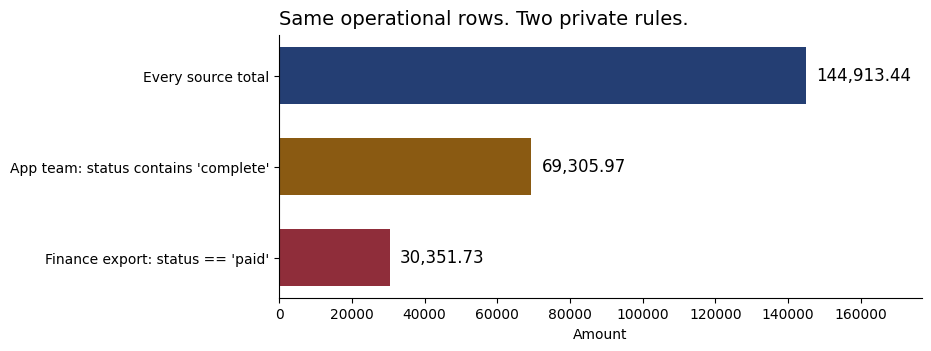

In [2]:
app_revenue = revenue_as_app_team(orders)
finance_revenue = revenue_as_finance_export(orders)
everything = naive_source_total(orders)
print(f"Sum of every source total_amount: {everything:,.2f}")
print(f"App team's 'completed' revenue:   {app_revenue:,.2f}")
print(f"Finance export's 'paid' revenue:  {finance_revenue:,.2f}")
print(f"Gap between the two consumers:    {abs(app_revenue - finance_revenue):,.2f}")
bar_compare(
    [
        ("Every source total", everything, C_SOURCE),
        ("App team: status contains 'complete'", app_revenue, C_WARN),
        ("Finance export: status == 'paid'", finance_revenue, C_BAD),
    ],
    "Same operational rows. Two private rules.",
    "Amount",
)


> **Ask the room.** Both queries are read-only. Is the orders database now an acceptable place for this work?

> **Instructor note.** Let them answer. Do not resolve it. You want "a replica would be fine" on the board. The next section takes that apart. Do not turn this chart into a debate about the correct revenue formula. The formula is the evidence that the rules have escaped the platform. The work of this hour is to land a copy that still contains the original rows.

**What you should observe.** One population, three totals, and a gap of about 39,000. The app team treats any status containing "complete" as revenue. Finance keeps only the exact string `paid`. Neither team stored the rows they summed. They borrowed checkout's current table.

**Production lesson.** Ingestion exists so the company has its own copy of what the source sent, taken off the transaction path, and kept after the source has moved on.


# 2 - The Operational Database Is the Wrong Store

**0:08-0:18**

**What we're solving.** Say precisely what a copy has to preserve that the application database will not.

**The engineering problem.** Operational storage is current state. An ingestion landing has to be evidence: the row as it was observed, kept when the application replaces it.


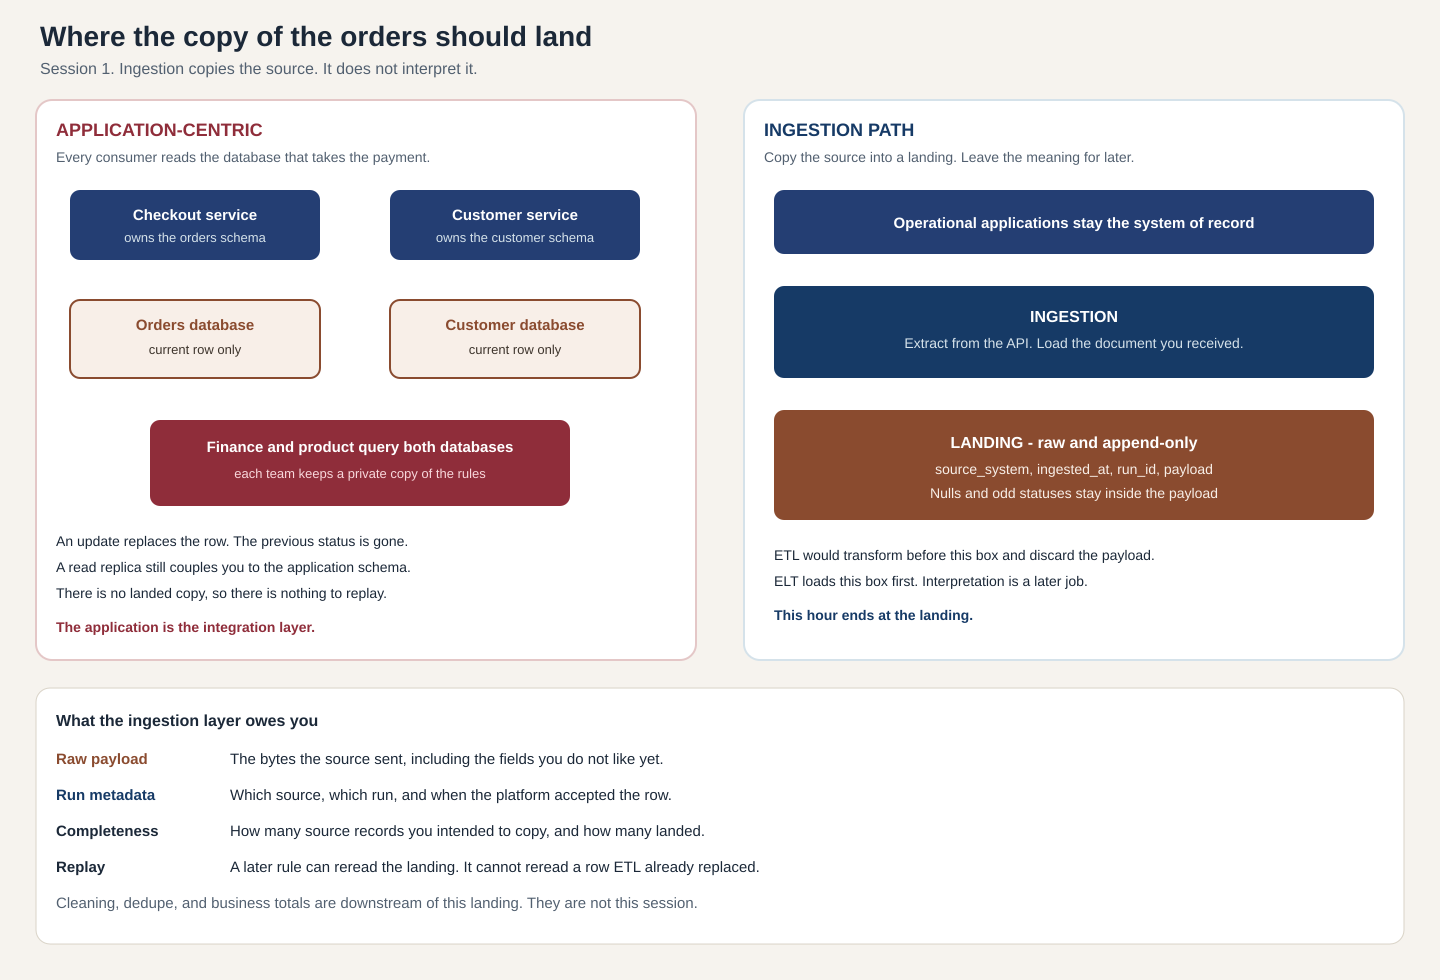

In [3]:
display(SVG(filename=str(ROOT / "docs" / "medallion_architecture.svg")))


### Walk the left side, then the right side

**Left.** Checkout owns the orders schema. Finance reaches into that database. The integration layer is the application.

**Right.** The applications stay the system of record. Ingestion copies what they expose. The landing is append-only and raw. This hour ends at that box.

There is no cleaning step on this diagram. A landing that already "fixed" the order is an ETL load, and we are about to see what that costs.


In [4]:
table = OperationalTable(orders)
changelog = ChangeLog()
before = table.get(1100)
changelog.observe(before)
after = table.update(1100, status="refunded", updated_at="2026-10-15T09:00:00Z")
changelog.observe(after)

print("Operational table now holds one status:", after["status"])
display(pd.DataFrame(
    [{"version": i + 1, "status": version["status"], "updated_at": version["updated_at"]}
     for i, version in enumerate(changelog.versions(1100))]
))
print("The table can still return the pre-refund status:", table.get(1100)["status"] == before["status"])


Operational table now holds one status: refunded


,version,status,updated_at
0,1,completed,2026-07-19T22:00:00Z
1,2,refunded,2026-10-15T09:00:00Z


The table can still return the pre-refund status: False


In [5]:
report = imperfection_report(orders)
print("What the source actually contains")
display(pd.Series(report).to_frame("orders"))
print("Order 1001, unchanged")
print(json.dumps(samples["messy"], indent=2))


What the source actually contains


,orders
orders,500
null_customer_id,14
null_product_id,13
null_currency,22
noncanonical_currency,101
noncanonical_status,57
amount_mismatch,18
updated_before_created,10
optional_channel_present,46
tied_updated_at_pairs,1


Order 1001, unchanged
{
  "order_id": 1001,
  "customer_id": null,
  "product_id": null,
  "quantity": 1,
  "unit_price": 69.27,
  "total_amount": 70.38,
  "currency": null,
  "status": "COMPLETED",
  "created_at": "2026-08-28T04:50:00Z",
  "updated_at": "2026-08-27T23:50:00Z",
  "channel": "web"
}


> **Ask the room.** A read replica of the orders database solves which of these problems?

**What you should observe.** After the refund, the operational table has one row. The previous status exists only because we appended it ourselves. The source population is also dirty on purpose: null customers, null currencies, mismatched totals, backwards timestamps, and more than one spelling of the same status. Order 1001 carries several of those at once. `COMPLETED`, a null currency, a total of 70.38 against a unit price of 69.27.

**What a replica does and does not do.** It can move the scan off the primary. It still serves current state, still follows the application schema, and still has no landed history once the row is updated. There is nothing to replay, because nothing was copied out.

**Production lesson.** The ingestion landing is not a nicer view of the orders table. It is a retained observation. If the observation is cleaned on the way in, the observation is gone.


# 3 - ETL versus ELT

**0:18-0:38**

**What we're solving.** Decide whether the raw order still exists after the load.

**The engineering problem.** ETL transforms, then loads the result. The warehouse receives a cleaned row. ELT extracts and loads the source document first. The transform, if it happens at all, is a later reader of that landing. It is not part of ingestion.


**ETL, in one line.** Pull the order, apply today's rule, store the result. The API's spelling, nulls, and original total do not survive unless some other system kept them.

**ELT, in one line.** Pull the order, store the document, stop. A later job may read that document and apply a rule. Ingestion has already finished.

Use ETL when the raw payload cannot be stored, or when the rule is small, stable, and owned by the same team as the source. Use ELT when the rule will change and the landing has to remain evidence. Commerce rules change.


In [6]:
order = samples["messy"]
loaded = etl_load(order)
landed = ingest(order, run_id="session1_preview", ingested_at=INGESTED_AT)

print("SOURCE")
print(json.dumps(order, indent=2))
print("ETL loaded only this")
print(json.dumps(loaded, indent=2))
print("ELT landing")
print(json.dumps(landed, indent=2))
print("payload equals the source:", landed["payload"] == order)
print("original total still in the ETL row:", loaded["total_amount"] == order["total_amount"])
print("source keys dropped by ETL:", sorted(set(order) - set(loaded)))


SOURCE
{
  "order_id": 1001,
  "customer_id": null,
  "product_id": null,
  "quantity": 1,
  "unit_price": 69.27,
  "total_amount": 70.38,
  "currency": null,
  "status": "COMPLETED",
  "created_at": "2026-08-28T04:50:00Z",
  "updated_at": "2026-08-27T23:50:00Z",
  "channel": "web"
}
ETL loaded only this
{
  "order_id": 1001,
  "customer_id": null,
  "status": "completed",
  "currency": null,
  "total_amount": 69.27,
  "order_date": "2026-08-28"
}
ELT landing
{
  "source_system": "orders_api",
  "ingested_at": "2026-10-15T09:00:00Z",
  "run_id": "session1_preview",
  "source_record_id": 1001,
  "payload": {
    "order_id": 1001,
    "customer_id": null,
    "product_id": null,
    "quantity": 1,
    "unit_price": 69.27,
    "total_amount": 70.38,
    "currency": null,
    "status": "COMPLETED",
    "created_at": "2026-08-28T04:50:00Z",
    "updated_at": "2026-08-27T23:50:00Z",
    "channel": "web"
  }
}
payload equals the source: True
original total still in the ETL row: False
source k

Orders at the source:                 500
ETL rows loaded:                      500
ETL rows that still have the original total: 482
ELT payloads identical to the source: 500


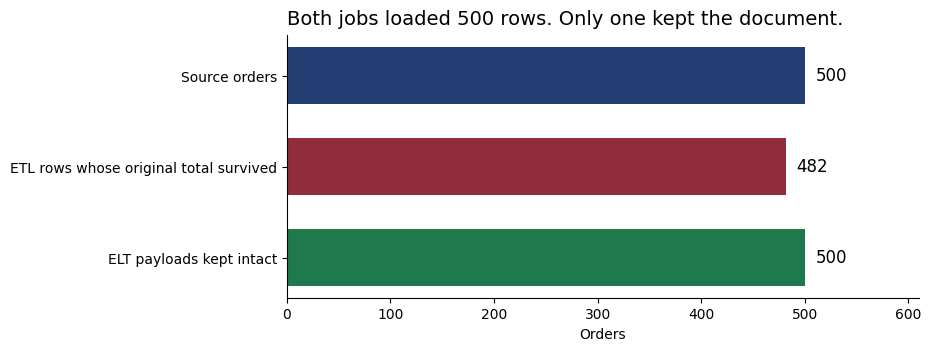

In [7]:
etl_rows = [etl_load(order) for order in orders]
landed_rows = ingest_batch(orders, run_id="full_landing", ingested_at=INGESTED_AT)
payloads_kept = sum(row["payload"] == source for row, source in zip(landed_rows, orders))
original_totals_kept = sum(
    loaded["total_amount"] == source["total_amount"] for loaded, source in zip(etl_rows, orders)
)
print(f"Orders at the source:                 {len(orders)}")
print(f"ETL rows loaded:                      {len(etl_rows)}")
print(f"ETL rows that still have the original total: {original_totals_kept}")
print(f"ELT payloads identical to the source: {payloads_kept}")
bar_compare(
    [
        ("Source orders", float(len(orders)), C_SOURCE),
        ("ETL rows whose original total survived", float(original_totals_kept), C_BAD),
        ("ELT payloads kept intact", float(payloads_kept), C_OK),
    ],
    "Both jobs loaded 500 rows. Only one kept the document.",
    "Orders",
)


> **Ask the room.** Next quarter the business wants the original status spelling and the original total, not the value we recomputed from price times quantity. Which load can answer that without going back to checkout?

**What you should observe.** ETL rewrote `COMPLETED` to `completed`, replaced 70.38 with 69.27, and dropped `channel`, `unit_price`, `created_at`, and `updated_at`. The job can report 500 rows loaded. The source document is not among them. Across the full population, most original totals do not survive, because the transform "fixed" them. ELT wrapped the same document with `source_system`, `ingested_at`, `run_id`, and `source_record_id`. All 500 payloads still match the source.

**Production lesson.** ELT does not mean the data stays dirty forever. It means ingestion does not spend the evidence. The landing is the input to every later rule. An ETL load is the end of the evidence.

> **Instructor note.** If someone says "so ELT is just ETL with the transform moved," agree, and then point at the payload. The location of the transform is the whole design. Once it runs inside the load, you cannot undo it.


# 4 - What the Ingestion Layer Actually Stores

**0:38-0:50**

**What we're solving.** Name the landing so the room can tell it apart from a cleaned table and from a metric.

**The engineering problem.** Ingestion is finished when the source document is durable and attributable. It is not finished when the document has been made pleasant.


In [8]:
envelope = landed_rows[0]
print(json.dumps(envelope, indent=2))
print("Envelope keys:", list(envelope))
print("Payload keys:", list(envelope["payload"]))
frame = pd.DataFrame(
    [
        {
            "run_id": row["run_id"],
            "source_record_id": row["source_record_id"],
            "ingested_at": row["ingested_at"],
            "status_in_payload": row["payload"]["status"],
            "currency_in_payload": row["payload"]["currency"],
            "total_in_payload": row["payload"]["total_amount"],
        }
        for row in landed_rows[:6]
    ]
)
display(frame)


{
  "source_system": "orders_api",
  "ingested_at": "2026-10-15T09:00:00Z",
  "run_id": "full_landing",
  "source_record_id": 1001,
  "payload": {
    "order_id": 1001,
    "customer_id": null,
    "product_id": null,
    "quantity": 1,
    "unit_price": 69.27,
    "total_amount": 70.38,
    "currency": null,
    "status": "COMPLETED",
    "created_at": "2026-08-28T04:50:00Z",
    "updated_at": "2026-08-27T23:50:00Z",
    "channel": "web"
  }
}
Envelope keys: ['source_system', 'ingested_at', 'run_id', 'source_record_id', 'payload']
Payload keys: ['order_id', 'customer_id', 'product_id', 'quantity', 'unit_price', 'total_amount', 'currency', 'status', 'created_at', 'updated_at', 'channel']


,run_id,source_record_id,ingested_at,status_in_payload,currency_in_payload,total_in_payload
0,full_landing,1001,2026-10-15T09:00:00Z,COMPLETED,None,70.38
1,full_landing,1002,2026-10-15T09:00:00Z,Pending,usd,99.88
2,full_landing,1003,2026-10-15T09:00:00Z,shipped,Usd,21.50
3,full_landing,1004,2026-10-15T09:00:00Z,shipped,US$,209.22
4,full_landing,1005,2026-10-15T09:00:00Z,paid,USD,418.85
5,full_landing,1006,2026-10-15T09:00:00Z,paid,USD,389.16


**What each field is for.**

- **payload.** The source document. Order 1001 is still `COMPLETED`, still null, still 70.38.
- **source_system.** Which contract produced the document, when a second source arrives.
- **ingested_at.** When the platform accepted the row. This is the platform clock, not `updated_at`.
- **run_id.** Which execution wrote the line, so a bad load can be found.
- **source_record_id.** The source identity, lifted out so you can count the landing without parsing every payload.

**What this layer refuses to do.** It does not repair status, currency, or money. It does not drop a row because a customer id is missing. It does not publish a total. A downstream job can do those things by reading the landing. Doing them here deletes the input that job would have used.

**Production lesson.** Call this landing Bronze if that is the name your platform uses. The name is not the point. The contract is: append-only, raw, and attributable. Everything after that contract is a different session.

> **Ask the room.** Someone proposes to uppercase the status during the load so analysts are not confused. What do they destroy, and who can no longer rebuild yesterday's rule?


# 5 - A Load Can Succeed and Still Be Wrong

**0:50-1:00**

**What we're solving.** Separate "the task exited" from "the landing contains the source."

**The engineering problem.** Ingestion can lose records while returning success, and it can keep records twice. Both are properties of the landing, visible before any later job runs.


Source orders:     500
Lines landed:      50
Not landed:        450


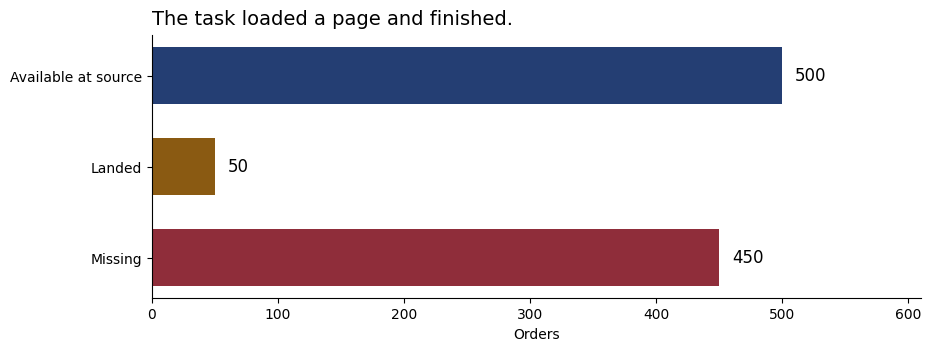

In [9]:
partial = ingest_batch(orders[:50], run_id="partial", ingested_at=INGESTED_AT)
print(f"Source orders:     {len(orders)}")
print(f"Lines landed:      {len(partial)}")
print(f"Not landed:        {len(orders) - len(partial)}")
bar_compare(
    [
        ("Available at source", float(len(orders)), C_SOURCE),
        ("Landed", float(len(partial)), C_WARN),
        ("Missing", float(len(orders) - len(partial)), C_BAD),
    ],
    "The task loaded a page and finished.",
    "Orders",
)


{'lines': 1000, 'distinct_orders': 500, 'duplicate_lines': 500}
Run ids in the landing: ['run_a', 'run_b']


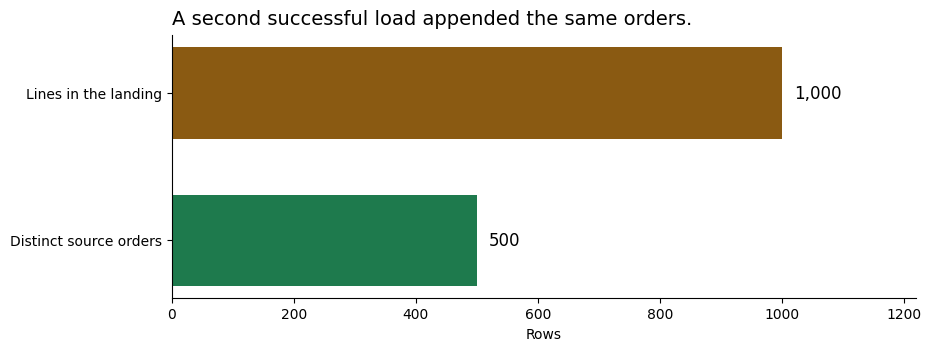

In [10]:
first = ingest_batch(orders, run_id="run_a", ingested_at=INGESTED_AT)
second = ingest_batch(orders, run_id="run_b", ingested_at="2026-10-15T09:05:00Z")
combined = landing_summary(first + second)
print(combined)
print("Run ids in the landing:", sorted({row["run_id"] for row in first + second}))
bar_compare(
    [
        ("Lines in the landing", float(combined["lines"]), C_WARN),
        ("Distinct source orders", float(combined["distinct_orders"]), C_OK),
    ],
    "A second successful load appended the same orders.",
    "Rows",
)


> **Ask the room.** The first task exited 0 and wrote 50 rows. The second pair of tasks each exited 0 and the landing now has 1,000 lines. Which of those runs failed?

**What you should observe.** Fifty landed rows is a successful write and an incomplete ingestion. The source had 500. The landing cannot report that gap unless the run records both numbers. The second picture is the other failure: nothing in checkout changed, two runs appended the same documents, and the landing holds 1,000 lines for 500 orders. The `run_id` tells you it happened. The landing did not collapse them.

**What reliable ingestion means.**

- **Completeness.** Intended source records compared with landed records. A green exit is not that comparison.
- **The raw document.** A rerun, or a new rule, reads the payload. ETL already replaced it.
- **Attribution.** `run_id` and `ingested_at` make a duplicate load visible.
- **A named delivery guarantee.** This landing is append-only. Writing the same document twice leaves two lines. That is at-least-once. Hiding the duplicate inside the load would also hide the evidence. A later reader can collapse on `source_record_id` plus the payload. That reader is not the ingestion layer.

**Production lesson.** The ingestion layer is trustworthy when an operator can answer, from the landing alone: what did the source send, which run accepted it, and did this run land the population it claimed?

### Handoff

We now have a contract for the first box in the platform. It copies operational orders and stops. It keeps the dirt. It can be incomplete. It can contain the same order twice, and it must show that.

Next session builds that copy for real. We call the Orders API, watch a single request land 50 of 500, page the rest, retry a failed call, kill the worker, and look at the duplicate page a restart appends. Order 1001 arrives as `COMPLETED`, with a null currency and a total of 70.38. The landing's job is to keep it that way.
